In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_path = '../codelab'

datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    subset='training'
)   

validation_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

test_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    shuffle=False
)

Found 640 images belonging to 2 classes.


Found 160 images belonging to 2 classes.
Found 160 images belonging to 2 classes.


In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(1, activation='sigmoid')  # Menggunakan 1 unit dengan sigmoid karena klasifikasi biner (bike/car)
])

model.summary()

c:\Users\Titan\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,034,177 (72.61 MB)

 Trainable params: 19,034,177 (72.61 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',  # Karena hanya ada 2 kelas (bike dan car)
    metrics=['accuracy']
)

In [6]:
epochs = 20

history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=validation_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_steps=validation_generator.samples // validation_generator.batch_size
)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 486ms/step - accuracy: 0.5578 - loss: 0.8725 - val_accuracy: 0.6875 - val_loss: 0.6182
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 231ms/step - accuracy: 0.7656 - loss: 0.5091 - val_accuracy: 0.8000 - val_loss: 0.4347
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 259ms/step - accuracy: 0.8813 - loss: 0.3057 - val_accuracy: 0.8562 - val_loss: 0.3326
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 232ms/step - accuracy: 0.9187 - loss: 0.1816 - val_accuracy: 0.9000 - val_loss: 0.3346
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 219ms/step - accuracy: 0.9594 - loss: 0.1061 - val_accuracy: 0.8687 - val_loss: 0.3312
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 212ms/step - accuracy: 0.9781 - loss: 0.0675 - val_accuracy: 0.9000 - val_loss: 0.3341
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 229ms/step - accuracy: 0.9641 - loss: 0.0933 - val_accuracy: 0.8938 - val_loss: 0.3196
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 216ms/step - accuracy: 0.9812 - loss: 0.0449 - val_accuracy: 0

In [7]:
loss, accuracy = model.evaluate(test_generator)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9000 - loss: 0.6629
Test Loss: 0.6629
Test Accuracy: 0.9000


In [8]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

def classify_new_image(image_path):
    # Memuat dan mengubah ukuran gambar agar sesuai dengan input model (150x150)
    img = image.load_img(image_path, target_size=(150, 150))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0  # Normalisasi seperti pada data training
    
    # Melakukan prediksi menggunakan model
    prediction = model.predict(img_array)
    probability = prediction[0][0]
    
    # Menentukan kelas berdasarkan probabilitas (sigmoid)
    if probability > 0.5:
        predicted_class = 'car'
        confidence = probability * 100
    else:
        predicted_class = 'bike'
        confidence = (1 - probability) * 100
        
    # Menampilkan gambar hasil prediksi
    plt.imshow(img)
    plt.title(f"Predicted: {predicted_class} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()
    
    return predicted_class

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


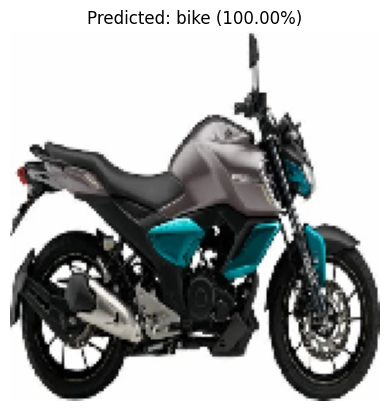

Hasil Prediksi: bike


In [10]:
# Masukkan path/lokasi file gambar yang ingin diuji di sini
image_to_classify = '../codelab/Bike-20261026T040810Z-1-001/bike/Bike (10).png'

# Memanggil fungsi klasifikasi
predicted_label = classify_new_image(image_to_classify)
print(f"Hasil Prediksi: {predicted_label}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


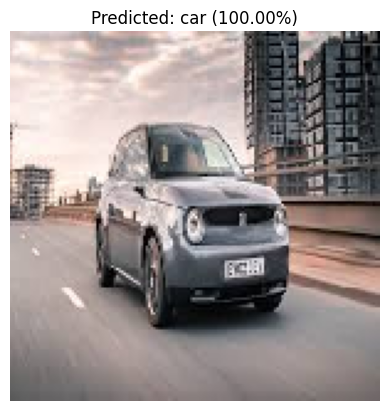

Hasil Prediksi: car


In [11]:
# Masukkan path/lokasi file gambar yang ingin diuji di sini
image_to_classify = '../codelab/Car-20261026T040810Z-1-001/car/Car (10).jpeg'

# Memanggil fungsi klasifikasi
predicted_label = classify_new_image(image_to_classify)
print(f"Hasil Prediksi: {predicted_label}")